# Milestone 4: Integrated Pipeline

Combines the Milestone 3 detector and the Milestone 1 classifier into one system (`src/pipeline.py`):
the detector finds the faces, the classifier names each one.

* **Part A:** how the Milestone 1 classifier does on detector face crops, before and after adapting it.
* **Part B:** choose the detector threshold and which model gives the final name, on the validation split.
* **Part C:** results on the held-out test split.

Outputs go to `results/milestone4/`.

#### 0. Environment setup (local Jupyter or Google Colab)
Same cell as the other notebooks: on Colab it mounts Drive and installs the requirements, locally it finds the repo root.

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/rasmussenj03/IE7615-Group3-Project1.git"
COLAB_USE_DRIVE = True  # False -> clone into /content (outputs are lost when the runtime ends)
COLAB_REPO_DIR = ("/content/drive/MyDrive/IE7615-Group3-Project1" if COLAB_USE_DRIVE
                  else "/content/IE7615-Group3-Project1")
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if COLAB_USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
    if not Path(COLAB_REPO_DIR, "src").is_dir():
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
        clone = subprocess.run(["git", "clone", "-q", REPO_URL.replace("https://", f"https://{token}@"),
                                COLAB_REPO_DIR], capture_output=True)
        if clone.returncode != 0:
            raise RuntimeError("git clone failed - check the GITHUB_TOKEN secret and repo access")
        subprocess.run(["git", "-C", COLAB_REPO_DIR, "remote", "set-url", "origin", REPO_URL])
    os.chdir(COLAB_REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    root = Path.cwd()
    while not (root / "src" / "pipeline.py").exists() and root != root.parent:
        root = root.parent
    os.chdir(root)

PROJECT_ROOT = Path.cwd()

In [2]:
import json

import matplotlib.pyplot as plt
import pandas as pd
import torch

from src import detection_eval as de
from src.adapt_classifier import accuracy, collect_crops, train
from src.pipeline import CLASSIFIER, SETTINGS, CelebrityPipeline, load_classifier, predict_split, use_identity

RETRAIN = False  # True retrains the adapted classifier even if it exists
OUT_DIR = PROJECT_ROOT / "results" / "milestone4"
OUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
M3 = json.loads((PROJECT_ROOT / "results" / "milestone3" / "sweep" / "operating_point.json").read_text())
print("Device:", DEVICE, "| Milestone 3 operating point:", M3)

Device: cpu | Milestone 3 operating point: {'model': 'results/milestone3/sweep/best_model.pt', 'training_run': 'aug_light', 'imgsz': 640, 'conf': 0.8, 'nms_iou': 0.7, 'agnostic_nms': False, 'selected_on': 'validation F1'}


---
## Part A: Adapt the classifier to face crops
Every labelled face of the val and test images is cut out with its ground-truth box, the way the detector
would box it.

In [3]:
# Face crops of the val and test splits
crops = {split: collect_crops(split) for split in ("val", "test")}
{split: len(crops[split][0]) for split in crops}

{'val': 564, 'test': 543}

In [4]:
# Milestone 1 classifier (CNN_2) on these crops, before adaptation
m1_model = load_classifier(PROJECT_ROOT / "checkpoints" / "efficientnet_b0_ft.pt", DEVICE)
before = {split: round(float(accuracy(m1_model, *crops[split], DEVICE)[0]), 3) for split in crops}
before

{'val': 0.656, 'test': 0.611}

In [5]:
# Fine-tune it on the training crops (about 5-15 min), or load the saved model
if RETRAIN or not CLASSIFIER.is_file():
    train(DEVICE)
history = pd.read_csv(OUT_DIR / "classifier_adaptation.csv")
history

epoch 1: train loss 0.647, val accuracy 0.918
epoch 2: train loss 0.466, val accuracy 0.933
epoch 3: train loss 0.433, val accuracy 0.959
epoch 4: train loss 0.413, val accuracy 0.961
epoch 5: train loss 0.401, val accuracy 0.947
Best validation accuracy 0.961, saved /Users/pmodi/Desktop/P2/Rhea/NU Grad/IE 7615/Project 1/IE7615-Group3-Project1/checkpoints/efficientnet_b0_crops.pt


,epoch,train_loss,val_accuracy
0,1,0.646893,0.918440
1,2,0.466052,0.932624
2,3,0.433485,0.959220
3,4,0.413119,0.960993
4,5,0.401314,0.946809


In [6]:
# Adapted classifier on the same crops
model = load_classifier(CLASSIFIER, DEVICE)
after, probs = {}, {}
for split in crops:
    after[split], probs[split] = accuracy(model, *crops[split], DEVICE)
crop_results = pd.DataFrame({"before adaptation": before, "after adaptation": after})
crop_results.to_csv(OUT_DIR / "classifier_on_crops.csv")
crop_results.round(3)

,before adaptation,after adaptation
val,0.656,0.961
test,0.611,0.864


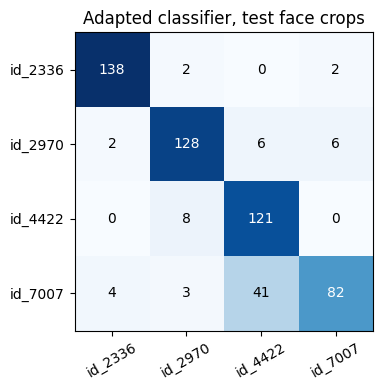

In [7]:
# Confusion matrix on the test crops
test_table = crops["test"][1].assign(pred=probs["test"].argmax(1))
cm = pd.crosstab(test_table["label"].map(dict(enumerate(de.CLASS_NAMES))),
                 test_table["pred"].map(dict(enumerate(de.CLASS_NAMES))), rownames=["true"], colnames=["predicted"])
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(cm.values, cmap="Blues")
ax.set_xticks(range(4), cm.columns, rotation=30)
ax.set_yticks(range(4), cm.index)
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm.values[i, j], ha="center", va="center",
                color="white" if cm.values[i, j] > cm.values.max() / 2 else "black")
ax.set_title("Adapted classifier, test face crops")
fig.tight_layout(); fig.savefig(OUT_DIR / "classifier_confusion_test.png", dpi=180); plt.show()

---
## Part B: Choose the pipeline settings on the validation split
The pipeline runs once on every val image; then each detector threshold and each identity source (detector or
classifier) is scored with the Milestone 3 matching (same identity, IoU >= 0.5). The best F1 is saved.

In [8]:
# Run the pipeline on every val image (low threshold; thresholds are applied below)
pipe = CelebrityPipeline(device=DEVICE)
val_records = predict_split(pipe, de.split_images("val"))

In [9]:
# F1 for every threshold and identity source
rows = []
for identity in ("detector", "classifier"):
    for conf in (0.25, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9):
        overall, _ = de.evaluate(use_identity(val_records, identity), conf)
        rows.append(dict(identity=identity, det_conf=conf, **overall))
val_sweep = pd.DataFrame(rows)
val_sweep.to_csv(OUT_DIR / "val_sweep.csv", index=False)
val_sweep.pivot(index="det_conf", columns="identity", values="F1").round(3)

identity,classifier,detector
det_conf,,
0.25,0.944,0.966
0.40,0.948,0.967
0.50,0.950,0.964
0.60,0.953,0.967
0.70,0.952,0.969
0.80,0.949,0.969
0.90,0.938,0.954


In [10]:
# Save the best setting (read by the pipeline, the gallery and the demo)
best = val_sweep.loc[val_sweep["F1"].idxmax()]
settings = dict(det_conf=float(best["det_conf"]), nms_iou=0.7, imgsz=640, identity=best["identity"])
SETTINGS.write_text(json.dumps(settings, indent=2))
pipe.settings.update(settings)
settings

{'det_conf': 0.7, 'nms_iou': 0.7, 'imgsz': 640, 'identity': 'detector'}

---
## Part C: Test results
The Milestone 3 detector on its own (its own operating point) against the pipeline with each identity source.

In [11]:
# Run the pipeline and the Milestone 3 detector alone on every test image
test_images = de.split_images("test")
test_records = predict_split(pipe, test_images)
m3_records = []
for path in test_images:
    m3_records += de.predict_split(pipe.detector, [path], nms_iou=M3["nms_iou"], agnostic_nms=M3["agnostic_nms"],
                                   imgsz=M3["imgsz"], device=DEVICE)

In [12]:
# Overall and per-identity scores
systems = {"Milestone 3 detector only": (m3_records, M3["conf"]),
           "Pipeline, detector names faces": (use_identity(test_records, "detector"), settings["det_conf"]),
           "Pipeline, classifier names faces": (use_identity(test_records, "classifier"), settings["det_conf"])}
rows, per_class = [], []
for name, (records, conf) in systems.items():
    overall, classes = de.evaluate(records, conf)
    rows.append(dict(system=name, det_conf=conf, **overall))
    per_class += [dict(system=name, identity=c, F1=v["F1"]) for c, v in classes.items()]
test_results = pd.DataFrame(rows)
test_results.to_csv(OUT_DIR / "test_results.csv", index=False)
test_results[["system", "det_conf", "precision", "recall", "F1", "mean_matched_IoU", "wrong_identity", "missed"]].round(3)

,system,det_conf,precision,recall,F1,mean_matched_IoU,wrong_identity,missed
0,Milestone 3 detector only,0.8,0.965,0.919,0.942,0.971,16,28
1,"Pipeline, detector names faces",0.7,0.946,0.930,0.938,0.970,21,17
2,"Pipeline, classifier names faces",0.7,0.865,0.851,0.858,0.971,64,17


In [13]:
# F1 per identity
pd.DataFrame(per_class).pivot(index="identity", columns="system", values="F1").round(3)

system,Milestone 3 detector only,"Pipeline, classifier names faces","Pipeline, detector names faces"
identity,,,
id_2336,0.965,0.948,0.968
id_2970,0.975,0.901,0.968
id_4422,0.923,0.826,0.906
id_7007,0.895,0.727,0.902


**Do the two models agree?** For every test box on a labelled face: how often the detector and the classifier
give the same name, and how often the final name is right in each case.

In [14]:
# Final name correct or not, for faces where the models agree vs. disagree
rows = []
for r in use_identity(test_records, settings["identity"]):
    a = de.analyze_image(r, settings["det_conf"])
    keep = r["scores"] >= settings["det_conf"]
    for gi, det, cls, final in zip(a["pred_gt"], r["detector"][keep], r["classifier"][keep], a["classes"]):
        if gi is not None:
            rows.append(dict(agree=det == cls, correct=final == r["gt_classes"][gi]))
agreement = pd.DataFrame(rows).groupby("agree").agg(faces=("correct", "size"), accuracy=("correct", "mean"))
agreement["share"] = agreement["faces"] / agreement["faces"].sum()
agreement.to_csv(OUT_DIR / "test_agreement.csv")
agreement.round(3)

,faces,accuracy,share
agree,,,
False,62,0.823,0.118
True,464,0.978,0.882
